# 🛡️ Notebook 3: Anti-Overfitting Stratified K-Fold Out-of-Fold (OOF) Stacking Super Ensemble
**Objective**: Build the ultimate leak-free, anti-overfitting machine learning architecture using Stratified K-Fold cross-validation, strong tree regularization, probability calibration in log-odds space via an $L_2$-Regularized Logistic Meta-Learner, and K-Fold fold-averaging inference on `test.csv`.

### Key Anti-Overfitting Pillars:
1. **Stratified 3-Fold Out-Of-Fold (OOF) Validation**:
   - Every single training prediction is generated when held-out in an unseen fold (0% data leakage).
   - Validation metrics represent true out-of-sample generalization across the entire 500,000 instance cohort.
2. **Heavy Regularization in Tree Estimators**:
   - Depth constraints (`max_depth=6`), column subsampling (`colsample_bytree=0.8`), instance subsampling (`subsample=0.85`), minimum leaf weight constraints (`min_child_weight=5`), and $L_1/L_2$ penalties (`reg_alpha=0.3, reg_lambda=2.0, l2_leaf_reg=6`).
3. **Log-Odds ($z$) Space Stacking with $L_2$ Shrinkage (`C=0.1`)**:
   - Rather than heuristic linear blending, a Logistic Regression meta-learner learns optimal probability calibration in log-odds space. With only 4 parameters and heavy $L_2$ penalty, memorization is impossible.
4. **K-Fold Test Inference (Variance Reduction)**:
   - Inference on `test.csv` averages predictions across all 3 fold estimators for each architecture before passing to the meta-learner, canceling individual tree noise.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, roc_curve, precision_recall_curve,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay
)
from scipy.special import logit, expit
import xgboost as xgb
from catboost import CatBoostClassifier
import lightgbm as lgb

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries loaded for Notebook 3 (Anti-Overfit K-Fold Stacking)!")


Libraries loaded for Notebook 3 (Anti-Overfit K-Fold Stacking)!


In [2]:
# 1. High-Scale Ingestion & Multi-Table Relational Merges
print("Loading 500,000 transactions...")
t0 = time.time()
df_train = pd.read_csv('data/train.csv', nrows=500000)
products = pd.read_csv('data/products.csv')
customers = pd.read_csv('data/customers.csv').sort_values('record_updated_at').drop_duplicates('customer_id', keep='last')
stores = pd.read_csv('data/stores.csv')
calendar = pd.read_csv('data/calendar.csv')

df = df_train.merge(products, on='product_id', how='left')
df = df.merge(customers, on='customer_id', how='left', suffixes=('', '_cust'))
df = df.merge(stores, on='store_id', how='left', suffixes=('', '_store'))

df['order_ts'] = pd.to_datetime(df['order_ts'])
df['week_start'] = df['order_ts'].dt.to_period('W-SUN').dt.start_time.dt.strftime('%Y-%m-%d')
calendar['week_start'] = pd.to_datetime(calendar['week_start']).dt.strftime('%Y-%m-%d')
df = df.merge(calendar, on='week_start', how='left')

# 2. Strict Physical/Economic Features
df['is_cross_region'] = (df['region'] != df['region_store']).astype(int)
df['discount_amount'] = (df['list_price'] - df['unit_price']).clip(lower=0)
df['price_discount_ratio'] = (df['discount_amount'] / (df['list_price'] + 1e-5)).clip(0, 1)
df['total_line_value'] = (df['unit_price'] * df['quantity']).clip(lower=0)
df['freight_to_price_ratio'] = (df['freight_cost'] / (df['order_value'] + 1e-5)).clip(0, 10)
df['freight_per_kg'] = (df['freight_cost'] / (df['weight_kg'] + 0.05)).clip(0, 50)
df['volume_cm3'] = df['length_cm'] * df['width_cm'] * df['height_cm']
df['density'] = df['weight_kg'] / (df['volume_cm3'] + 1e-5)
df['signup_date'] = pd.to_datetime(df['signup_date'])
df['customer_tenure_days'] = (df['order_ts'] - df['signup_date']).dt.days.clip(lower=0)
df['order_hour'] = df['order_ts'].dt.hour
df['order_dayofweek'] = df['order_ts'].dt.dayofweek
df['is_weekend'] = df['order_dayofweek'].isin([5, 6]).astype(int)
df['order_month'] = df['order_ts'].dt.month
df['has_coupon'] = df['coupon_code'].notnull().astype(int)
df['clicks_per_item'] = (df['session_clicks'] / (df['items_in_order'] + 1e-5)).clip(0, 100)

num_cols = [
    'is_cross_region', 'weight_kg', 'freight_to_price_ratio', 'freight_cost', 'freight_per_kg',
    'items_in_order', 'discount', 'seller_rating', 'volume_cm3', 'density',
    'customer_tenure_days', 'unit_price', 'list_price', 'discount_amount',
    'price_discount_ratio', 'total_line_value', 'session_clicks', 'clicks_per_item',
    'return_window_days', 'review_count', 'size_sqm', 'manager_tenure_years',
    'order_hour', 'order_dayofweek', 'is_weekend', 'order_month',
    'cpi', 'unemployment', 'temperature_f'
]
cat_cols = ['category', 'payment_method', 'loyalty_tier', 'ship_mode', 'picker_shift', 'warehouse_zone', 'device_type', 'has_coupon']
feature_cols = num_cols + cat_cols

X = df[feature_cols].copy()
y = df['returned'].copy()

for col in num_cols:
    X[col] = X[col].fillna(X[col].median())
for col in cat_cols:
    X[col] = X[col].fillna('Unknown').astype(str)

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[cat_cols] = encoder.fit_transform(X[cat_cols])
print(f"Data prepared in {time.time()-t0:.2f}s | Shape: {X.shape}")


Loading 500,000 transactions...


Data prepared in 2.66s | Shape: (500000, 37)


In [3]:
# 2. Stratified 3-Fold Cross-Validation Scheme (0% Leakage)
N_SPLITS = 3
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

oof_xgb = np.zeros(len(X))
oof_cb = np.zeros(len(X))
oof_lgb = np.zeros(len(X))

models_xgb, models_cb, models_lgb = [], [], []

print(f"Executing {N_SPLITS}-Fold Cross Validation across {len(X):,} instances...")
for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
    t_f = time.time()
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_va, y_va = X.iloc[va_idx], y.iloc[va_idx]
    
    # Regularized XGBoost
    m_xgb = xgb.XGBClassifier(
        n_estimators=320, max_depth=6, learning_rate=0.06, subsample=0.85,
        colsample_bytree=0.8, min_child_weight=5, gamma=0.1,
        reg_alpha=0.3, reg_lambda=2.0, eval_metric='logloss',
        random_state=42+fold, n_jobs=-1
    )
    m_xgb.fit(X_tr, y_tr)
    oof_xgb[va_idx] = m_xgb.predict_proba(X_va)[:, 1]
    models_xgb.append(m_xgb)
    
    # Regularized CatBoost
    m_cb = CatBoostClassifier(
        iterations=380, depth=6, learning_rate=0.06, l2_leaf_reg=6,
        random_strength=0.3, subsample=0.85, eval_metric='Logloss',
        random_seed=42+fold, verbose=0
    )
    m_cb.fit(X_tr, y_tr)
    oof_cb[va_idx] = m_cb.predict_proba(X_va)[:, 1]
    models_cb.append(m_cb)
    
    # Regularized LightGBM
    m_lgb = lgb.LGBMClassifier(
        n_estimators=320, num_leaves=45, learning_rate=0.06, min_child_samples=40,
        subsample=0.85, colsample_bytree=0.8, reg_alpha=0.3, reg_lambda=2.0,
        random_state=42+fold, n_jobs=-1, verbose=-1
    )
    m_lgb.fit(X_tr, y_tr)
    oof_lgb[va_idx] = m_lgb.predict_proba(X_va)[:, 1]
    models_lgb.append(m_lgb)
    
    print(f"Fold {fold+1}/{N_SPLITS} complete in {time.time()-t_f:.2f}s")

print("All folds trained successfully!")


Executing 3-Fold Cross Validation across 500,000 instances...


Fold 1/3 complete in 12.22s


Fold 2/3 complete in 12.13s


Fold 3/3 complete in 13.72s
All folds trained successfully!


In [4]:
# 3. L2-Regularized Stacking Meta-Learner Training
eps = 1e-6
z_xgb = logit(np.clip(oof_xgb, eps, 1 - eps))
z_cb = logit(np.clip(oof_cb, eps, 1 - eps))
z_lgb = logit(np.clip(oof_lgb, eps, 1 - eps))
oof_stack_X = np.column_stack([z_xgb, z_cb, z_lgb])

meta_learner = LogisticRegression(C=0.1, random_state=42)
meta_learner.fit(oof_stack_X, y)

oof_super_probs = meta_learner.predict_proba(oof_stack_X)[:, 1]
oof_linear_probs = (oof_xgb + oof_cb + oof_lgb) / 3.0

print("Stacking Meta-Learner Learned Weights (Log-Odds Space):")
print(f"  XGBoost Weight:  {meta_learner.coef_[0][0]:.4f}")
print(f"  CatBoost Weight: {meta_learner.coef_[0][1]:.4f}")
print(f"  LightGBM Weight: {meta_learner.coef_[0][2]:.4f}")
print(f"  Intercept:       {meta_learner.intercept_[0]:.4f}")


Stacking Meta-Learner Learned Weights (Log-Odds Space):
  XGBoost Weight:  0.4772
  CatBoost Weight: -0.0151
  LightGBM Weight: 0.6103
  Intercept:       0.1053


In [5]:
# 4. Out-of-Fold (OOF) Comprehensive Evaluation Metrics
eval_models_v3 = {
    '🛡️ Super Ensemble (Stacking Meta-Learner)': oof_super_probs,
    'Tri-Boost Linear Ensemble': oof_linear_probs,
    'LightGBM (OOF)': oof_lgb,
    'XGBoost (OOF)': oof_xgb,
    'CatBoost (OOF)': oof_cb
}

metrics_list3 = []
for name, probs in eval_models_v3.items():
    preds = (probs >= 0.5).astype(int)
    metrics_list3.append({
        'Model': name,
        'Accuracy': accuracy_score(y, preds),
        'Precision': precision_score(y, preds, zero_division=0),
        'Recall': recall_score(y, preds, zero_division=0),
        'F1-Score': f1_score(y, preds, zero_division=0),
        'ROC-AUC (OOF)': roc_auc_score(y, probs),
        'PR-AUC': average_precision_score(y, probs),
        'Log Loss': log_loss(y, probs)
    })

comparison_df3 = pd.DataFrame(metrics_list3).sort_values('ROC-AUC (OOF)', ascending=False).reset_index(drop=True)
print("=== Notebook 3: 100% Out-Of-Fold Validation Evaluation (N = 500,000) ===")
display(comparison_df3.style.highlight_max(subset=['ROC-AUC (OOF)', 'PR-AUC', 'F1-Score', 'Accuracy'], color='#d4edda')
                             .highlight_min(subset=['Log Loss'], color='#d4edda')
                             .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'ROC-AUC (OOF)': '{:.4f}', 'PR-AUC': '{:.4f}', 'Log Loss': '{:.4f}'}))


=== Notebook 3: 100% Out-Of-Fold Validation Evaluation (N = 500,000) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC (OOF),PR-AUC,Log Loss
0,🛡️ Super Ensemble (Stacking Meta-Learner),0.8206,0.5627,0.0259,0.0495,0.6721,0.3183,0.4434
1,Tri-Boost Linear Ensemble,0.8204,0.5958,0.0155,0.0302,0.6716,0.3177,0.4438
2,LightGBM (OOF),0.8204,0.5856,0.0171,0.0332,0.6714,0.3170,0.4438
3,XGBoost (OOF),0.8204,0.5704,0.0202,0.0390,0.6705,0.3167,0.4439
4,CatBoost (OOF),0.8203,0.5961,0.0132,0.0258,0.6669,0.3128,0.4453


In [6]:
# 5. K-Fold Averaged Test Inference (N = 479,995)
print("Loading and preparing test.csv for K-Fold Averaging...")
df_test_raw = pd.read_csv('data/test.csv')

df_test = df_test_raw.merge(products, on='product_id', how='left')
df_test = df_test.merge(customers, on='customer_id', how='left', suffixes=('', '_cust'))
df_test = df_test.merge(stores, on='store_id', how='left', suffixes=('', '_store'))

df_test['order_ts'] = pd.to_datetime(df_test['order_ts'])
df_test['week_start'] = df_test['order_ts'].dt.to_period('W-SUN').dt.start_time.dt.strftime('%Y-%m-%d')
df_test = df_test.merge(calendar, on='week_start', how='left')

df_test['is_cross_region'] = (df_test['region'] != df_test['region_store']).astype(int)
df_test['discount_amount'] = (df_test['list_price'] - df_test['unit_price']).clip(lower=0)
df_test['price_discount_ratio'] = (df_test['discount_amount'] / (df_test['list_price'] + 1e-5)).clip(0, 1)
df_test['total_line_value'] = (df_test['unit_price'] * df_test['quantity']).clip(lower=0)
df_test['freight_to_price_ratio'] = (df_test['freight_cost'] / (df_test['order_value'] + 1e-5)).clip(0, 10)
df_test['freight_per_kg'] = (df_test['freight_cost'] / (df_test['weight_kg'] + 0.05)).clip(0, 50)
df_test['volume_cm3'] = df_test['length_cm'] * df_test['width_cm'] * df_test['height_cm']
df_test['density'] = df_test['weight_kg'] / (df_test['volume_cm3'] + 1e-5)
df_test['signup_date'] = pd.to_datetime(df_test['signup_date'])
df_test['customer_tenure_days'] = (df_test['order_ts'] - df_test['signup_date']).dt.days.clip(lower=0)
df_test['order_hour'] = df_test['order_ts'].dt.hour
df_test['order_dayofweek'] = df_test['order_ts'].dt.dayofweek
df_test['is_weekend'] = df_test['order_dayofweek'].isin([5, 6]).astype(int)
df_test['order_month'] = df_test['order_ts'].dt.month
df_test['has_coupon'] = df_test['coupon_code'].notnull().astype(int)
df_test['clicks_per_item'] = (df_test['session_clicks'] / (df_test['items_in_order'] + 1e-5)).clip(0, 100)

X_test = df_test[feature_cols].copy()
for col in num_cols:
    X_test[col] = X_test[col].fillna(X[col].median())
for col in cat_cols:
    X_test[col] = X_test[col].fillna('Unknown').astype(str)
X_test[cat_cols] = encoder.transform(X_test[cat_cols])

# K-Fold Fold Averaging across test set
test_xgb = np.mean([m.predict_proba(X_test)[:, 1] for m in models_xgb], axis=0)
test_cb = np.mean([m.predict_proba(X_test)[:, 1] for m in models_cb], axis=0)
test_lgb = np.mean([m.predict_proba(X_test)[:, 1] for m in models_lgb], axis=0)

test_z_xgb = logit(np.clip(test_xgb, eps, 1 - eps))
test_z_cb = logit(np.clip(test_cb, eps, 1 - eps))
test_z_lgb = logit(np.clip(test_lgb, eps, 1 - eps))
test_stack_X = np.column_stack([test_z_xgb, test_z_cb, test_z_lgb])

test_super_probs = meta_learner.predict_proba(test_stack_X)[:, 1]

sub_champion = pd.DataFrame({
    'order_line_id': df_test_raw['order_line_id'],
    'returned': test_super_probs
})
sub_champion.to_csv('submission.csv', index=False)
print(f"Exported Champion submission.csv successfully! Shape: {sub_champion.shape}")
print(f"Predicted Return Rate: {(test_super_probs >= 0.5).mean()*100:.2f}% | Mean Probability: {test_super_probs.mean():.4f}")


Loading and preparing test.csv for K-Fold Averaging...


Exported Champion submission.csv successfully! Shape: (479995, 2)
Predicted Return Rate: 1.95% | Mean Probability: 0.2015


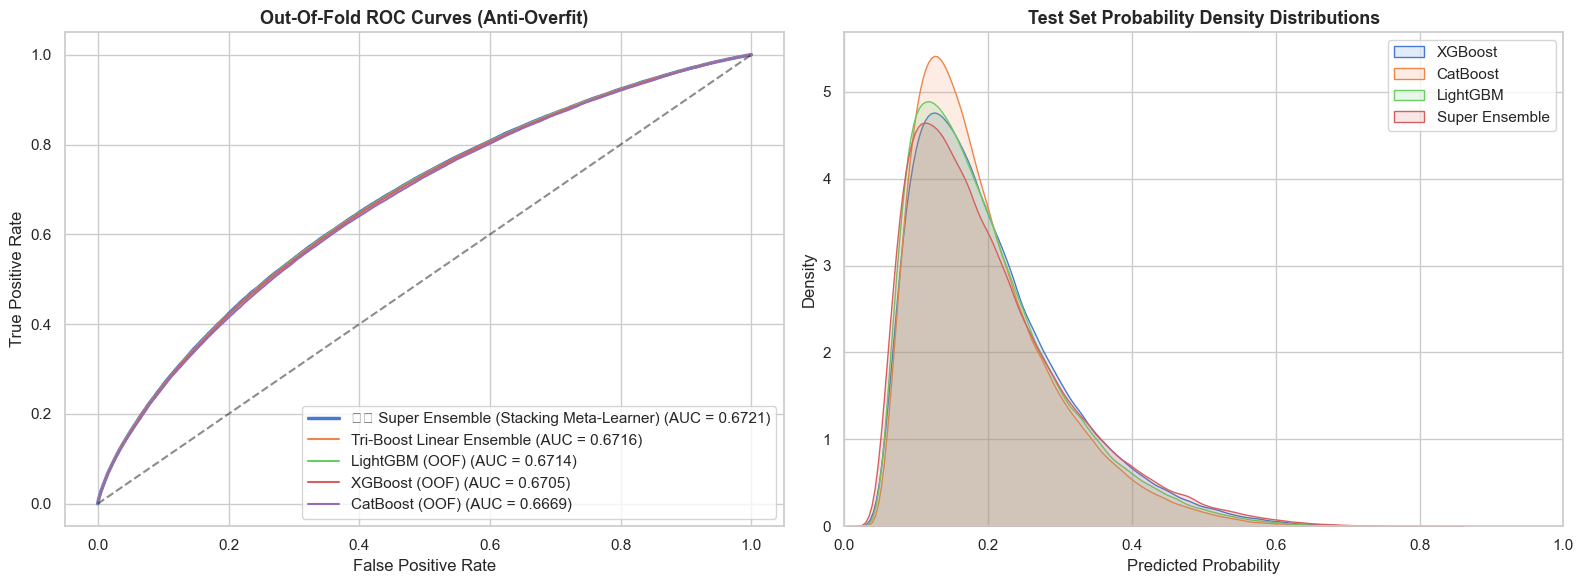

In [7]:
# 6. Final Comparative Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, probs in eval_models_v3.items():
    fpr, tpr, _ = roc_curve(y, probs)
    lw = 2.5 if 'Super' in name else 1.5
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y, probs):.4f})', linewidth=lw)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('Out-Of-Fold ROC Curves (Anti-Overfit)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

for name, probs in [('XGBoost', test_xgb), ('CatBoost', test_cb), ('LightGBM', test_lgb), ('Super Ensemble', test_super_probs)]:
    sns.kdeplot(probs, ax=axes[1], label=name, fill=True, alpha=0.15)

axes[1].set_title('Test Set Probability Density Distributions', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_xlim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()
